In [98]:
!pip install numpy pandas matplotlib seaborn scikit-learn joblib openpyxl

Defaulting to user installation because normal site-packages is not writeable


In [99]:
# Data processing
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Machine learning algorithms
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    adjusted_rand_score,
    silhouette_score
)

# Cross-validation and tuning
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Save models
import joblib

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [100]:
df = pd.read_csv("crop_recommendation.csv")

# Display first five rows
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [101]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))

# First five rows
display(df.head())

Dataset Shape: (2200, 8)

Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB

Statistical Summary:


,N,P,K,temperature,humidity,ph,rainfall,label
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rice
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655,NaN
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389,NaN
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267,NaN
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686,NaN
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624,NaN
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508,NaN


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [102]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0


In [103]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Fill numerical missing values
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values
for col in df.select_dtypes(exclude=np.number).columns:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Data cleaning completed!")

print("Remaining missing values:",
      df.isnull().sum().sum())

print("Remaining duplicates:",
      df.duplicated().sum())

Data cleaning completed!
Remaining missing values: 0
Remaining duplicates: 0


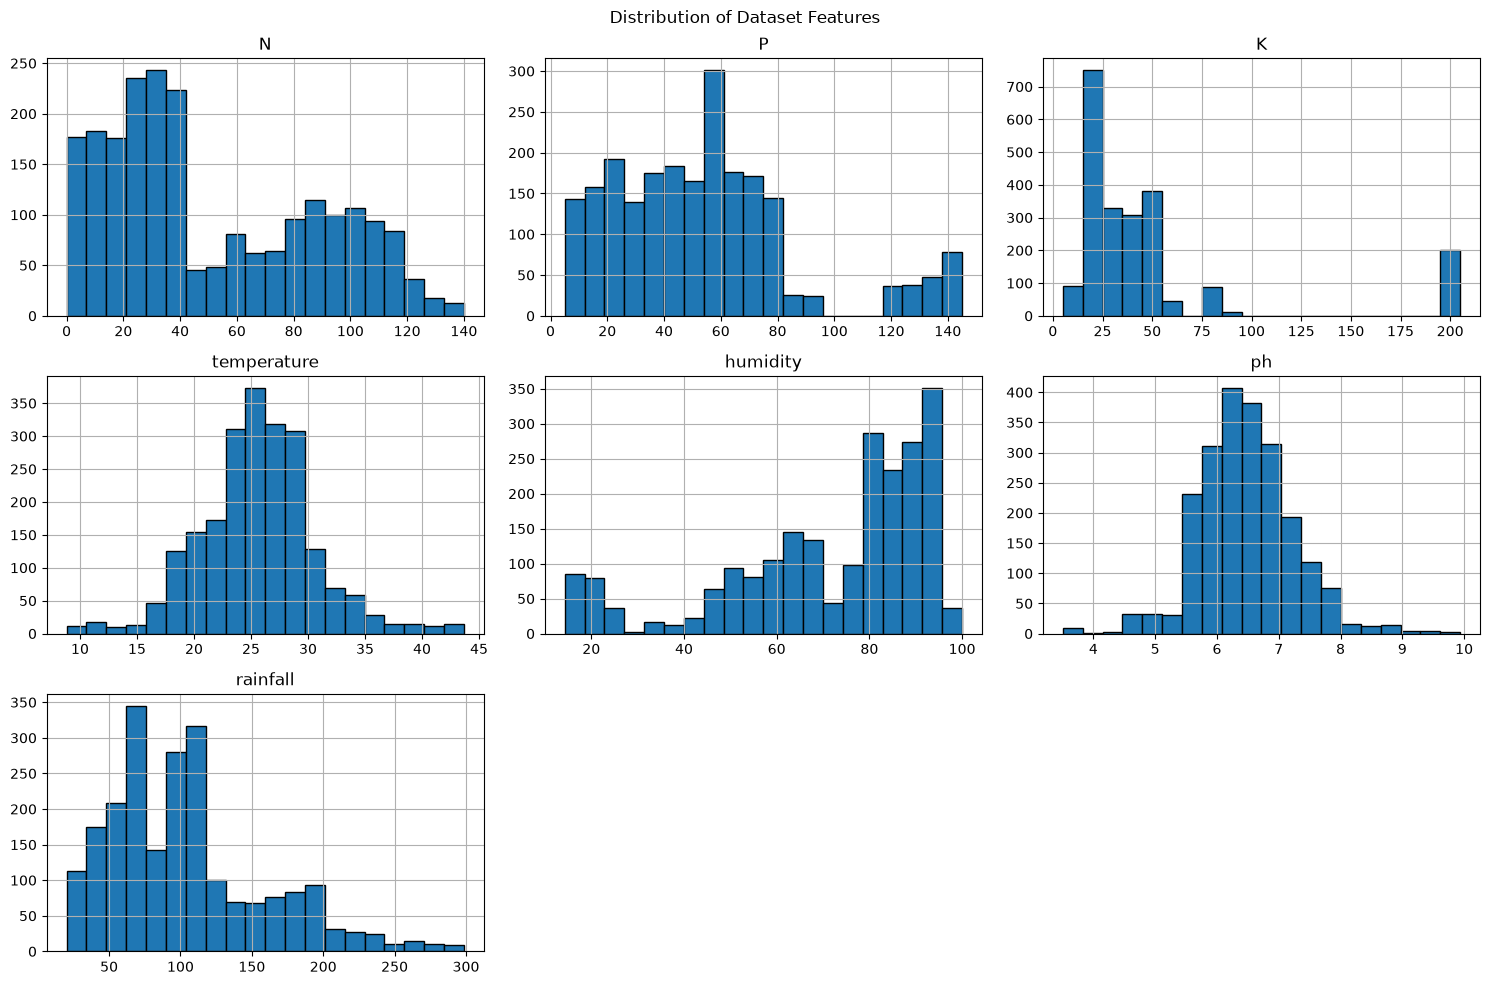

In [104]:
df.hist(
    figsize=(15, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Dataset Features")
plt.tight_layout()
plt.show()

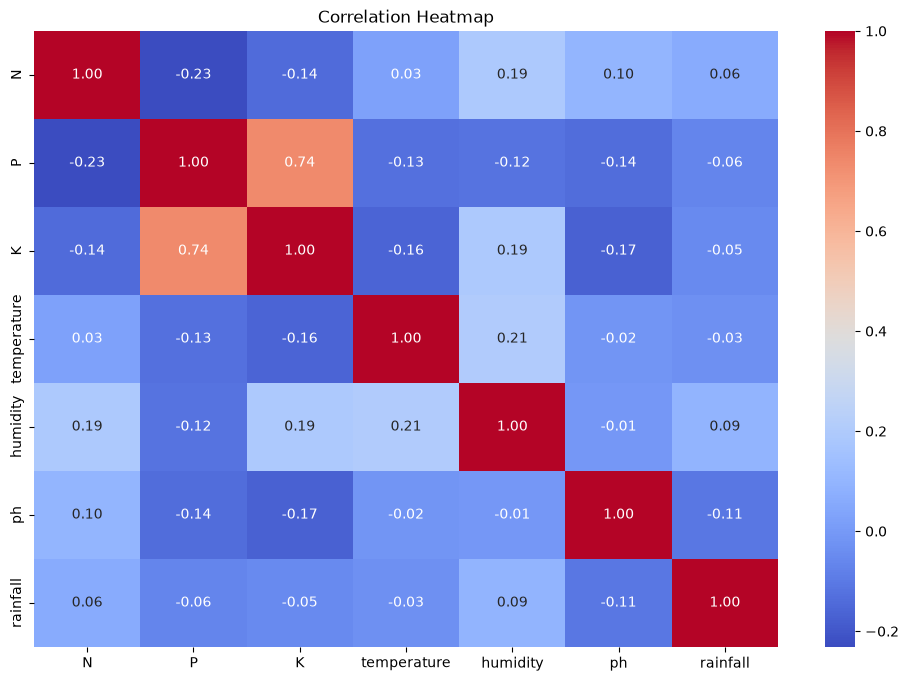

In [105]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

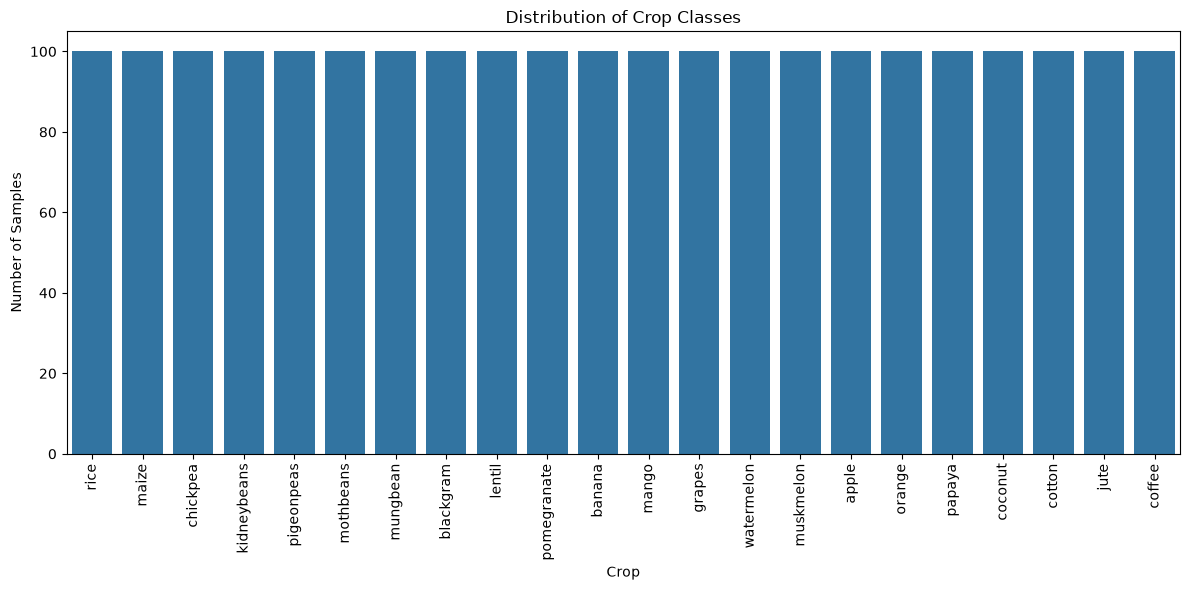

In [106]:
TARGET_COLUMN = 'label'

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x=TARGET_COLUMN,
    order=df[TARGET_COLUMN].value_counts().index
)

plt.title("Distribution of Crop Classes")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [107]:
# Define target column
TARGET_COLUMN = 'label'

# Separate input and output
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())

Input Features Shape: (2200, 7)
Target Shape: (2200,)

Input Features:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Target Classes:
['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


In [108]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original Classes:")
print(label_encoder.classes_)

print("\nEncoded Target:")
print(y_encoded[:10])

Original Classes:
['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']

Encoded Target:
[20 20 20 20 20 20 20 20 20 20]


In [109]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1760, 7)
Testing Data: (440, 7)


In [110]:
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed!
Processed training shape: (1760, 7)
Processed testing shape: (440, 7)


In [111]:
# Convert target into one-hot representation
number_of_classes = len(label_encoder.classes_)

y_train_onehot = np.eye(number_of_classes)[y_train]

# Create Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(
    X_train_processed,
    y_train_onehot
)

# Predict test data
linear_output = linear_model.predict(X_test_processed)

# Convert predicted scores into class labels
linear_predictions = np.argmax(
    linear_output,
    axis=1
)

print("Linear Regression training completed!")

Linear Regression training completed!


In [112]:
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train
logistic_model.fit(
    X_train_processed,
    y_train
)

# Predict
logistic_predictions = logistic_model.predict(
    X_test_processed
)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [113]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

# Train
knn_model.fit(
    X_train_processed,
    y_train
)

# Predict
knn_predictions = knn_model.predict(
    X_test_processed
)

print("KNN training completed!")

KNN training completed!


In [114]:
kmeans_model = KMeans(
    n_clusters=number_of_classes,
    random_state=42,
    n_init=10
)

# Train clustering model
kmeans_model.fit(X_train_processed)

# Predict clusters
kmeans_predictions = kmeans_model.predict(
    X_test_processed
)

print("K-Means training completed!")

K-Means training completed!


In [115]:
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

# Train
svm_model.fit(
    X_train_processed,
    y_train
)

# Predict
svm_predictions = svm_model.predict(
    X_test_processed
)

print("SVM training completed!")

SVM training completed!


In [116]:
# SGD Classifier with Learning Rate 0.001

sgd_model = SGDClassifier(
    loss='log_loss',
    learning_rate='constant',
    eta0=0.001,
    max_iter=2000,
    random_state=42
)

# Train model
sgd_model.fit(X_train_processed, y_train)

# Predict
sgd_predictions = sgd_model.predict(X_test_processed)

print("SGD Classifier training completed!")
print("Learning Rate: 0.001")

SGD Classifier training completed!
Learning Rate: 0.001


In [119]:
predictions = {
    'Linear Regression': linear_predictions,
    'Logistic Regression': logistic_predictions,
    'KNN': knn_predictions,
    'K-Means': kmeans_predictions,
    'SVM': svm_predictions,
    'SGD Classifier': sgd_predictions
}

In [120]:
results = []

for model_name, prediction in predictions.items():

    # Common clustering agreement metric
    ari = adjusted_rand_score(
        y_test,
        prediction
    )

    if model_name != 'K-Means':

        accuracy = accuracy_score(
            y_test, prediction
        )

        precision = precision_score(
            y_test,
            prediction,
            average='weighted',
            zero_division=0
        )

        recall = recall_score(
            y_test,
            prediction,
            average='weighted',
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            prediction,
            average='weighted',
            zero_division=0
        )

    else:
        accuracy = np.nan
        precision = np.nan
        recall = np.nan
        f1 = np.nan

    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ARI': ari
    })

# Create comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ARI
0,Linear Regression,0.7295,0.7367,0.7295,0.6767,0.6385
1,Logistic Regression,0.9727,0.9740,0.9727,0.9725,0.9451
2,KNN,0.9795,0.9804,0.9795,0.9793,0.9573
3,K-Means,NaN,NaN,NaN,NaN,0.6429
4,SVM,0.9841,0.9856,0.9841,0.9840,0.9669
5,SGD Classifier,0.8295,0.8732,0.8295,0.8182,0.7292


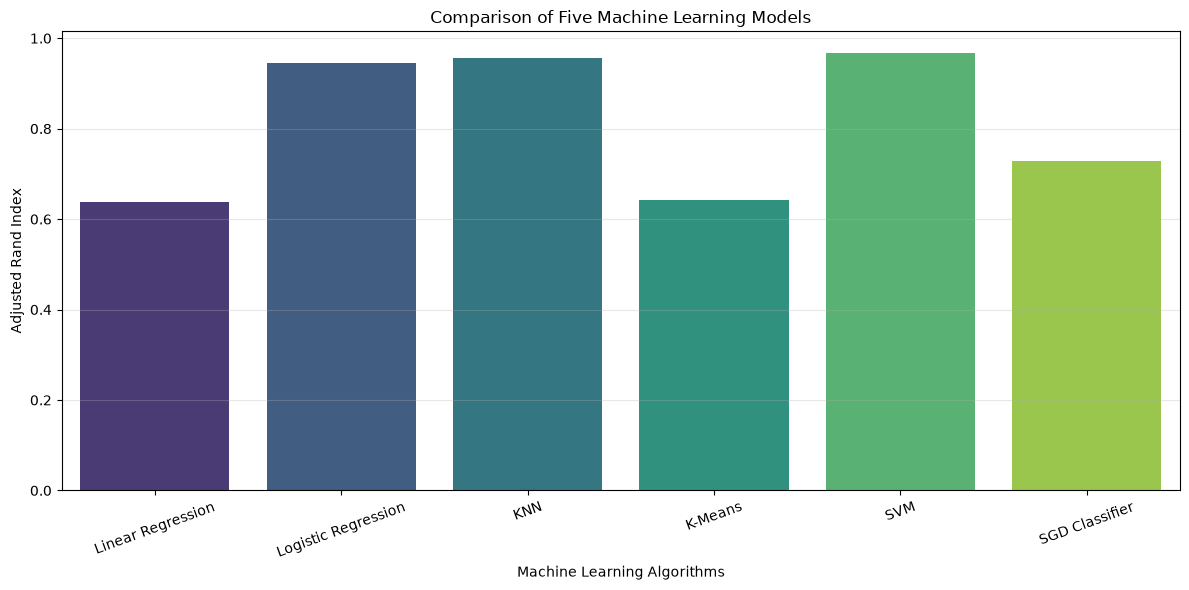

In [121]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='ARI',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("Comparison of Five Machine Learning Models")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Adjusted Rand Index")
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

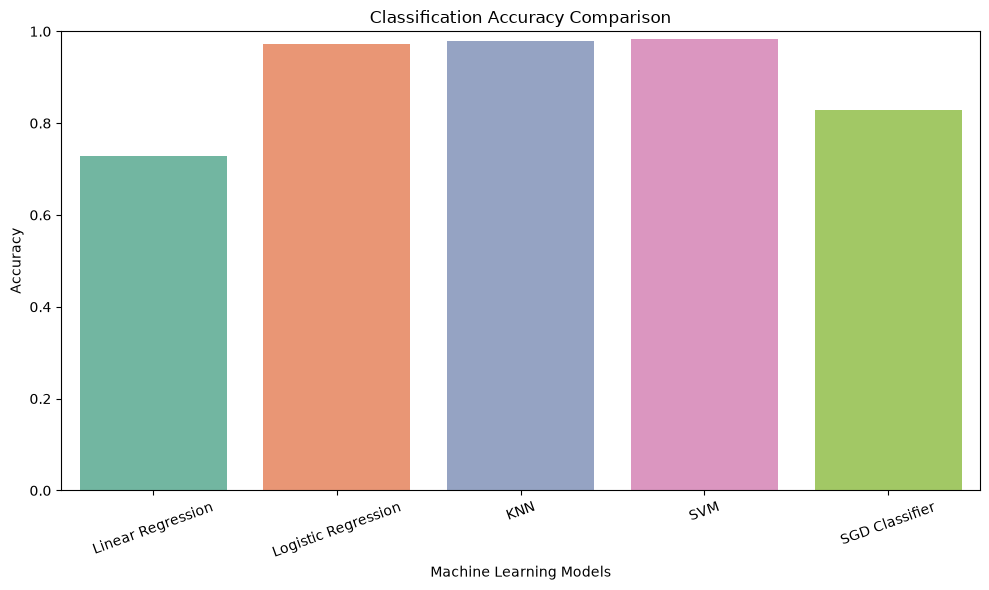

In [122]:
classification_results = results_df.dropna(
    subset=['Accuracy']
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=classification_results,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='Set2',
    legend=False
)

plt.title("Classification Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [123]:
if len(np.unique(kmeans_predictions)) > 1:

    silhouette = silhouette_score(
        X_test_processed,
        kmeans_predictions
    )

    print("K-Means Silhouette Score:",
          round(silhouette, 4))

else:
    silhouette = np.nan
    print("Silhouette Score cannot be calculated.")

K-Means Silhouette Score: 0.3224


In [124]:
# Sort models according to ARI
ranked_models = results_df.sort_values(
    by='ARI',
    ascending=False
).reset_index(drop=True)

# Select top three
top_3_models = ranked_models.head(3)

print("TOP 3 BEST PERFORMING MODELS")

display(top_3_models.round(4))

TOP 3 BEST PERFORMING MODELS


,Model,Accuracy,Precision,Recall,F1 Score,ARI
0,SVM,0.9841,0.9856,0.9841,0.9840,0.9669
1,KNN,0.9795,0.9804,0.9795,0.9793,0.9573
2,Logistic Regression,0.9727,0.9740,0.9727,0.9725,0.9451


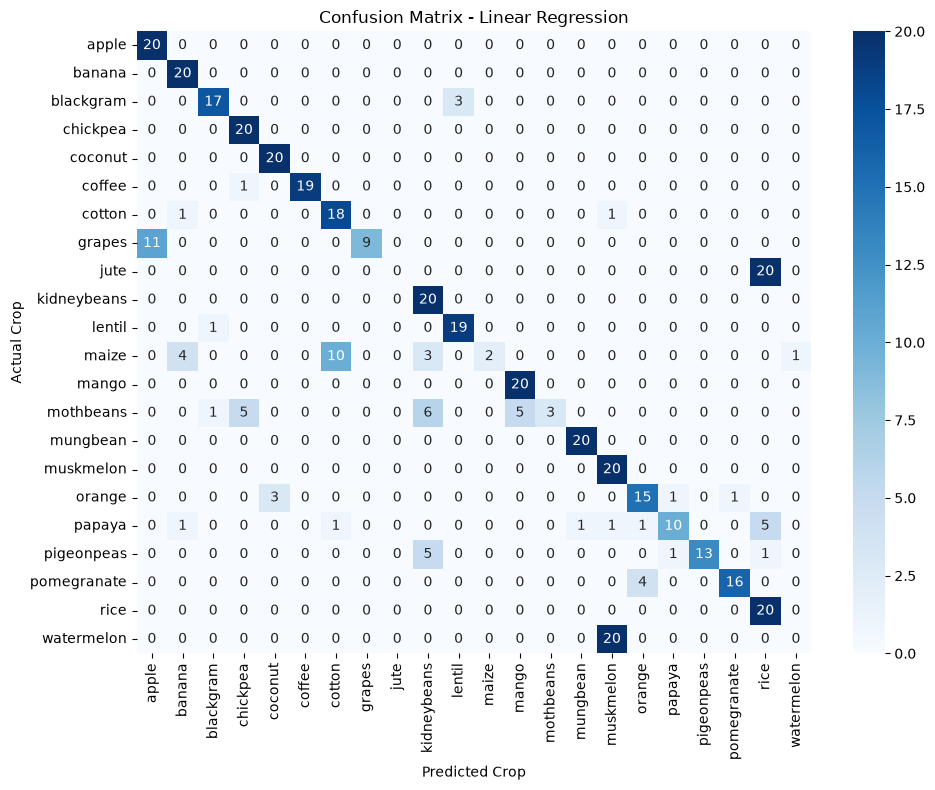

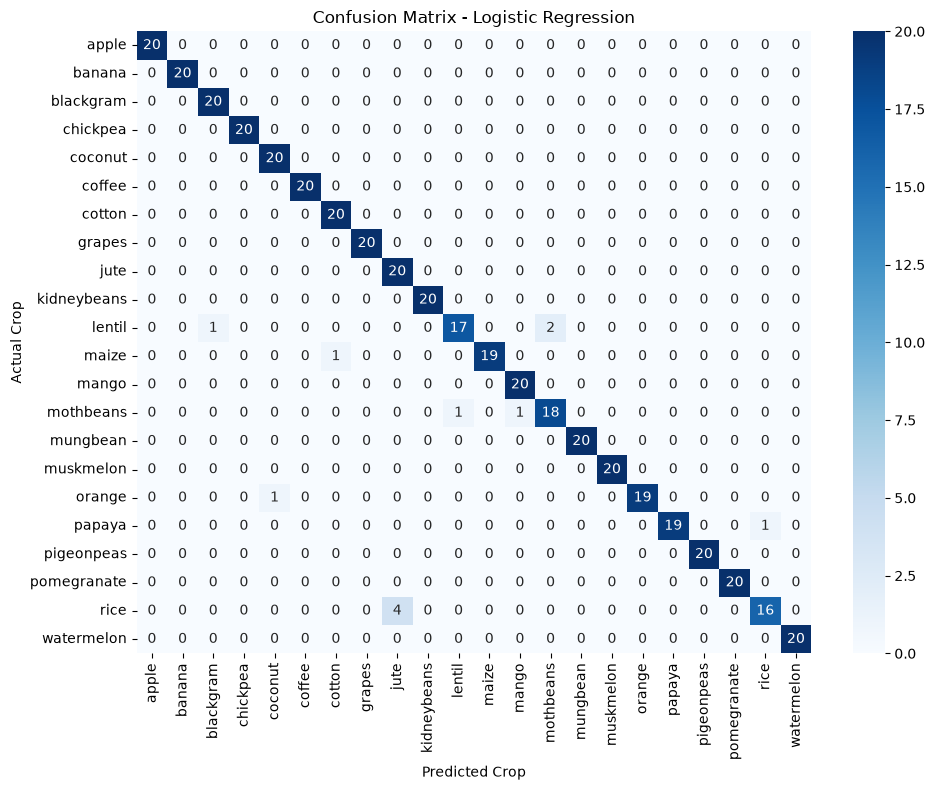

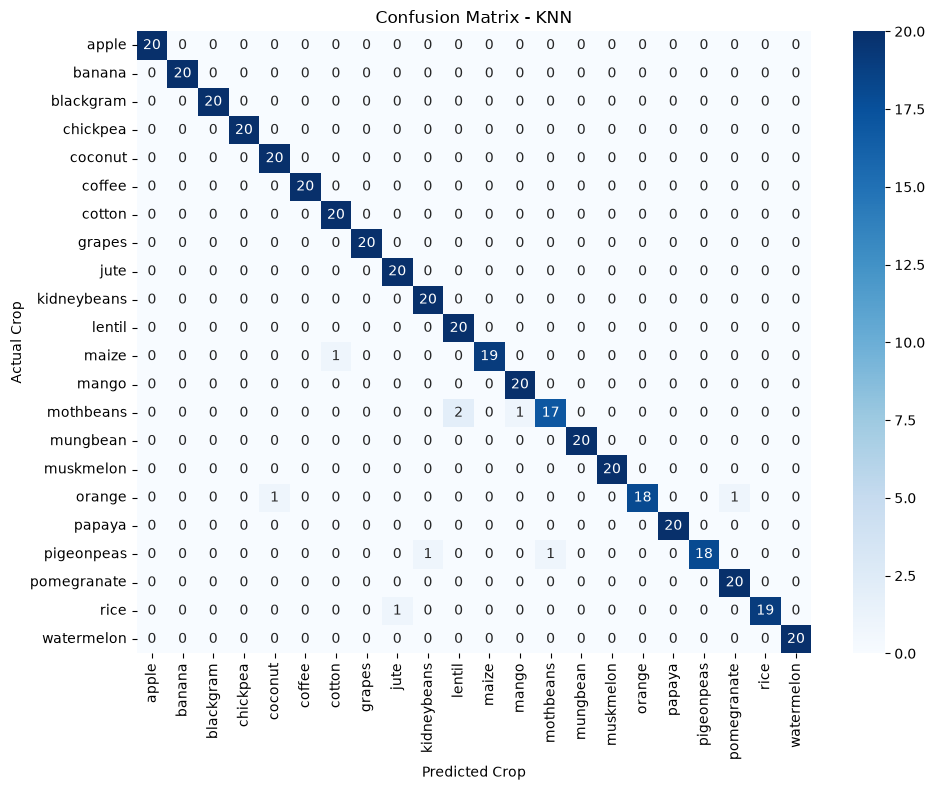

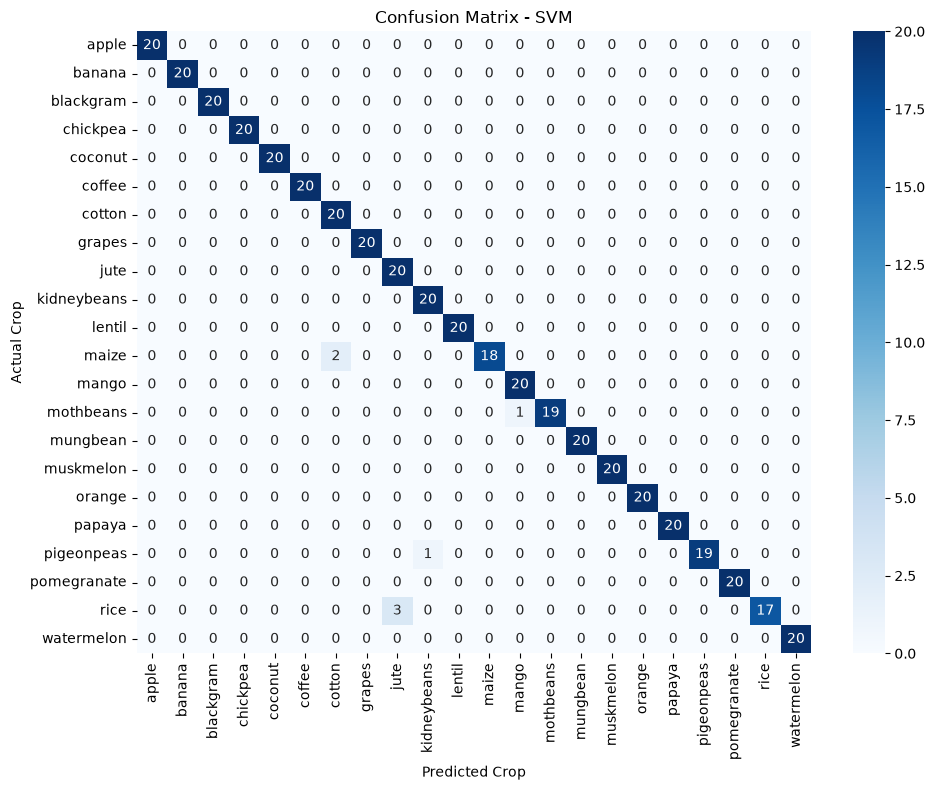

In [125]:
supervised_predictions = {
    'Linear Regression': linear_predictions,
    'Logistic Regression': logistic_predictions,
    'KNN': knn_predictions,
    'SVM': svm_predictions
}

for model_name, prediction in supervised_predictions.items():

    cm = confusion_matrix(
        y_test,
        prediction
    )

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Crop")
    plt.ylabel("Actual Crop")

    plt.tight_layout()
    plt.show()

In [126]:
for model_name, prediction in supervised_predictions.items():

    print("\n", "=" * 60)
    print("MODEL:", model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            prediction,
            labels=np.arange(number_of_classes),
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )


MODEL: Linear Regression
              precision    recall  f1-score   support

       apple       0.65      1.00      0.78        20
      banana       0.77      1.00      0.87        20
   blackgram       0.89      0.85      0.87        20
    chickpea       0.77      1.00      0.87        20
     coconut       0.87      1.00      0.93        20
      coffee       1.00      0.95      0.97        20
      cotton       0.62      0.90      0.73        20
      grapes       1.00      0.45      0.62        20
        jute       0.00      0.00      0.00        20
 kidneybeans       0.59      1.00      0.74        20
      lentil       0.86      0.95      0.90        20
       maize       1.00      0.10      0.18        20
       mango       0.80      1.00      0.89        20
   mothbeans       1.00      0.15      0.26        20
    mungbean       0.95      1.00      0.98        20
   muskmelon       0.48      1.00      0.65        20
      orange       0.75      0.75      0.75        20
 

In [127]:
logistic_parameters = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'],
    'max_iter': [2000]
}

logistic_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    logistic_parameters,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

logistic_grid.fit(
    X_train_processed,
    y_train
)

print("Best Parameters:",
      logistic_grid.best_params_)

print("Best Cross-validation Accuracy:",
      logistic_grid.best_score_)

Best Parameters: {'C': 100, 'max_iter': 2000, 'solver': 'lbfgs'}
Best Cross-validation Accuracy: 0.9818181818181818


In [128]:
logistic_parameters = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'],
    'max_iter': [2000]
}

logistic_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    logistic_parameters,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

logistic_grid.fit(
    X_train_processed,
    y_train
)

print("Best Parameters:",
      logistic_grid.best_params_)

print("Best Cross-validation Accuracy:",
      logistic_grid.best_score_)

Best Parameters: {'C': 100, 'max_iter': 2000, 'solver': 'lbfgs'}
Best Cross-validation Accuracy: 0.9818181818181818


In [129]:
knn_parameters = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_parameters,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

knn_grid.fit(
    X_train_processed,
    y_train
)

print("Best Parameters:",
      knn_grid.best_params_)

print("Best Cross-validation Accuracy:",
      knn_grid.best_score_)

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Best Cross-validation Accuracy: 0.98125


In [130]:
svm_parameters = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    SVC(),
    svm_parameters,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

svm_grid.fit(
    X_train_processed,
    y_train
)

print("Best Parameters:",
      svm_grid.best_params_)

print("Best Cross-validation Accuracy:",
      svm_grid.best_score_)

Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Cross-validation Accuracy: 0.9852272727272728


In [131]:
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_for_cv = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'SVM': SVC(
        kernel='rbf'
    )
}

cv_results = []

for name, model in models_for_cv.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', clone(preprocessor)),
        ('model', model)
    ])

    from sklearn.model_selection import cross_val_score

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Mean Accuracy': scores.mean(),
        'Standard Deviation': scores.std()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))

,Model,Mean Accuracy,Standard Deviation
0,Logistic Regression,0.9682,0.0066
1,KNN,0.9653,0.0121
2,SVM,0.9790,0.0103


In [132]:
# Get optimized models
best_logistic_model = logistic_grid.best_estimator_
best_knn_model = knn_grid.best_estimator_
best_svm_model = svm_grid.best_estimator_

# Generate optimized predictions
optimized_predictions = {
    'Logistic Regression': best_logistic_model.predict(
        X_test_processed
    ),

    'KNN': best_knn_model.predict(
        X_test_processed
    ),

    'SVM': best_svm_model.predict(
        X_test_processed
    )
}

# Calculate performance
for name, prediction in optimized_predictions.items():

    print("\nModel:", name)

    print("Accuracy:",
          round(accuracy_score(y_test, prediction), 4))

    print("Precision:",
          round(precision_score(
              y_test, prediction,
              average='weighted',
              zero_division=0
          ), 4))

    print("Recall:",
          round(recall_score(
              y_test, prediction,
              average='weighted',
              zero_division=0
          ), 4))

    print("F1 Score:",
          round(f1_score(
              y_test, prediction,
              average='weighted',
              zero_division=0
          ), 4))


Model: Logistic Regression
Accuracy: 0.9841
Precision: 0.9852
Recall: 0.9841
F1 Score: 0.984

Model: KNN
Accuracy: 0.9818
Precision: 0.9823
Recall: 0.9818
F1 Score: 0.9817

Model: SVM
Accuracy: 0.9886
Precision: 0.9896
Recall: 0.9886
F1 Score: 0.9887


In [133]:
# Get optimized models
best_logistic_model = logistic_grid.best_estimator_
best_knn_model = knn_grid.best_estimator_
best_svm_model = svm_grid.best_estimator_

# Generate optimized predictions
optimized_predictions = {
    'Logistic Regression': best_logistic_model.predict(
        X_test_processed
    ),

    'KNN': best_knn_model.predict(
        X_test_processed
    ),

    'SVM': best_svm_model.predict(
        X_test_processed
    )
}

# Calculate performance
for name, prediction in optimized_predictions.items():

    print("\nModel:", name)

    print("Accuracy:",
          round(accuracy_score(y_test, prediction), 4))

    print("Precision:",
          round(precision_score(
              y_test, prediction,
              average='weighted',
              zero_division=0
          ), 4))

    print("Recall:",
          round(recall_score(
              y_test, prediction,
              average='weighted',
              zero_division=0
          ), 4))

    print("F1 Score:",
          round(f1_score(
              y_test, prediction,
              average='weighted',
              zero_division=0
          ), 4))


Model: Logistic Regression
Accuracy: 0.9841
Precision: 0.9852
Recall: 0.9841
F1 Score: 0.984

Model: KNN
Accuracy: 0.9818
Precision: 0.9823
Recall: 0.9818
F1 Score: 0.9817

Model: SVM
Accuracy: 0.9886
Precision: 0.9896
Recall: 0.9886
F1 Score: 0.9887


In [134]:
# Keep the original Linear Regression and K-Means results
final_predictions = {
    'Linear Regression': linear_predictions,
    'K-Means': kmeans_predictions,
    'Logistic Regression': optimized_predictions[
        'Logistic Regression'
    ],
    'KNN': optimized_predictions['KNN'],
    'SVM': optimized_predictions['SVM']
}

final_results = []

for name, prediction in final_predictions.items():

    ari = adjusted_rand_score(
        y_test,
        prediction
    )

    if name != 'K-Means':

        accuracy = accuracy_score(y_test, prediction)

        precision = precision_score(
            y_test, prediction,
            average='weighted',
            zero_division=0
        )

        recall = recall_score(
            y_test, prediction,
            average='weighted',
            zero_division=0
        )

        f1 = f1_score(
            y_test, prediction,
            average='weighted',
            zero_division=0
        )

    else:
        accuracy = np.nan
        precision = np.nan
        recall = np.nan
        f1 = np.nan

    final_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ARI': ari
    })

final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.sort_values(
    by='ARI',
    ascending=False
).reset_index(drop=True)

display(final_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ARI
0,SVM,0.9886,0.9896,0.9886,0.9887,0.9758
1,Logistic Regression,0.9841,0.9852,0.9841,0.9840,0.9669
2,KNN,0.9818,0.9823,0.9818,0.9817,0.9616
3,K-Means,NaN,NaN,NaN,NaN,0.6429
4,Linear Regression,0.7295,0.7367,0.7295,0.6767,0.6385


In [135]:
top_three = final_results_df.head(3)

print("FINAL TOP THREE MODELS")
display(top_three.round(4))

print("\nBest model based on ARI:")

best_model_name = top_three.iloc[0]['Model']

print(best_model_name)

FINAL TOP THREE MODELS


,Model,Accuracy,Precision,Recall,F1 Score,ARI
0,SVM,0.9886,0.9896,0.9886,0.9887,0.9758
1,Logistic Regression,0.9841,0.9852,0.9841,0.9840,0.9669
2,KNN,0.9818,0.9823,0.9818,0.9817,0.9616



Best model based on ARI:
SVM


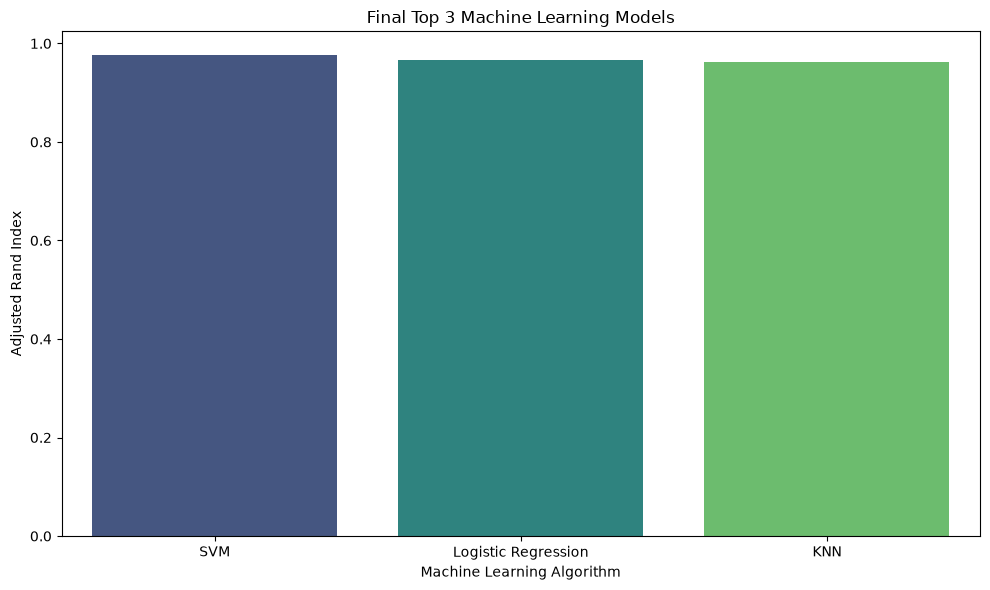

In [136]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_three,
    x='Model',
    y='ARI',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("Final Top 3 Machine Learning Models")
plt.ylabel("Adjusted Rand Index")
plt.xlabel("Machine Learning Algorithm")

plt.tight_layout()
plt.show()

In [137]:
all_models = {
    'Linear Regression': linear_model,
    'Logistic Regression': best_logistic_model,
    'KNN': best_knn_model,
    'K-Means': kmeans_model,
    'SVM': best_svm_model,
    'SGD Classifier': sgd_model
}

joblib.dump(all_models, 'all_trained_models.pkl')

['all_trained_models.pkl']

In [138]:
best_model = all_models[best_model_name]

joblib.dump(
    best_model,
    'best_model.pkl'
)

print("Best model saved:", best_model_name)

Best model saved: SVM


In [139]:
# Load saved model
loaded_model = joblib.load('best_model.pkl')

# Example new input
new_data = pd.DataFrame({
    'N': [90],
    'P': [42],
    'K': [43],
    'temperature': [40.5],
    'humidity': [80.0],
    'ph': [6.5],
    'rainfall': [200.0]
})

# Transform new input
new_data_processed = preprocessor.transform(new_data)

# Make prediction
prediction = loaded_model.predict(new_data_processed)

# Convert prediction to crop name if it is a supervised classifier
if best_model_name != 'K-Means':
    predicted_crop = label_encoder.inverse_transform(
        prediction.astype(int)
    )

    print("Predicted Crop:", predicted_crop[0])

else:
    print("Predicted Cluster:", prediction[0])

Predicted Crop: papaya


In [140]:
# Export all model results
final_results_df.to_excel(
    'model_comparison_results.xlsx',
    index=False
)

# Export top three models
top_three.to_excel(
    'top_three_models.xlsx',
    index=False
)

print("Results exported successfully!")

Results exported successfully!


In [141]:
print("=" * 60)
print("FINAL MACHINE LEARNING EXPERIMENT SUMMARY")
print("=" * 60)

print("\nDataset Information")
print("Total Samples:", len(df))
print("Total Features:", X.shape[1])
print("Total Classes:", number_of_classes)

print("\nAlgorithms Used:")
for name in final_predictions.keys():
    print("-", name)

print("\nTop Three Models:")
for index, row in top_three.iterrows():
    print(
        f"{index + 1}. {row['Model']} "
        f"| ARI: {row['ARI']:.4f}"
    )

print("\nBest Model:", best_model_name)

print("\nExperiment Completed Successfully!")
print("=" * 60)

FINAL MACHINE LEARNING EXPERIMENT SUMMARY

Dataset Information
Total Samples: 2200
Total Features: 7
Total Classes: 22

Algorithms Used:
- Linear Regression
- K-Means
- Logistic Regression
- KNN
- SVM

Top Three Models:
1. SVM | ARI: 0.9758
2. Logistic Regression | ARI: 0.9669
3. KNN | ARI: 0.9616

Best Model: SVM

Experiment Completed Successfully!
